# O modelo da Calculadora Agrícola

Elastic Net em scikit-learn, em 4 células. Rode de cima para baixo com **Shift + Enter**.

In [9]:
%pip install scikit-learn matplotlib openpyxl

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 8.4/8.4 MB 65.6 MB/s  0:00:00
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ------------------------- -------------- 23.9/37.4 MB 116.8 MB/s eta 0:00:01
   ---------------------------------------  37.2/37.4 MB 116.8 MB/s eta 0:00:01
   ---------------------------------------- 37.4/37.4 MB 76.1 MB/s  0:00:00

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
pip install matplotlib

SyntaxError: invalid syntax (842801469.py, line 1)

In [4]:
pip install sklearn

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
      
      More information is available at
      https://github.com/scikit-learn/sklearn-

In [10]:
# CÉLULA 1 — dados: clima do INMET por fase da planta + rendimento do IBGE
import warnings, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import GroupKFold, GridSearchCV
from media_historica import calcular_base_hist
warnings.filterwarnings("ignore")
%matplotlib inline
br = lambda v, c=2: f"{v:.{c}f}".replace(".", ",")

df  = pd.read_excel("df_tcc_modelo.xlsx", sheet_name="modelo")
pam = pd.read_excel("df_tcc_modelo.xlsx", sheet_name="pam_bruto")
FAIXAS = {"Soja (em grão)": (15, 100), "Milho (em grão)": (20, 250), "Trigo (em grão)": (10, 100)}
df = df[df["cobertura_ciclo"] >= 0.80]                                   # mesmos filtros do TCC
df = df[[lo <= r <= hi for r, (lo, hi) in zip(df["rendimento_sacas_ha"], df["cultura_tcc"].map(FAIXAS))]]
df = df.sort_values(["cod_municipio", "cultura_tcc", "ano_pam"]).reset_index(drop=True)
df["base_hist"], _ = calcular_base_hist(df, pam)                         # média das safras anteriores do município

X_COLS = [c for c in df.columns if c.startswith(("vegetativo_", "floracao_", "enchimento_"))] + ["base_hist"]
X, y, municipio = df[X_COLS], df["rendimento_sacas_ha"].values, df["cod_municipio"].values
print(f"{len(df)} safras de {df.cod_municipio.nunique()} municípios, de {df.ano_pam.min()} a {df.ano_pam.max()}")
print(f"{len(X_COLS)} variáveis de entrada  →  o modelo prevê o rendimento em sacas por hectare")

920 safras de 145 municípios, de 2020 a 2024
55 variáveis de entrada  →  o modelo prevê o rendimento em sacas por hectare


In [11]:
# CÉLULA 2 — o modelo: padronização Min-Max + Elastic Net (regressão linear com penalidades L1 e L2)
def novo_modelo():
    pipeline = Pipeline([("escala", MinMaxScaler()),
                         ("modelo", ElasticNet(max_iter=20000, random_state=42))])
    grade = {"modelo__alpha":    [0.001, 0.01, 0.1, 0.5, 1.0, 5.0],      # força da penalidade
             "modelo__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9, 0.95]}       # mistura entre L1 e L2
    return GridSearchCV(pipeline, grade, cv=GroupKFold(n_splits=4),      # escolhe a melhor das 36 combinações
                        scoring="neg_root_mean_squared_error", n_jobs=-1)

print("Modelo: MinMaxScaler → ElasticNet (36 combinações de alpha e l1_ratio)")

Modelo: MinMaxScaler → ElasticNet (36 combinações de alpha e l1_ratio)


In [12]:
# CÉLULA 3 — treino e teste: o modelo treina numa parte dos dados e prevê a parte escondida
def treinar_e_testar(rodadas):
    previsto = np.full(len(df), np.nan)
    for treino, teste in rodadas:
        mediana = X.iloc[treino].median()
        busca = novo_modelo()
        busca.fit(X.iloc[treino].fillna(mediana), y[treino], groups=municipio[treino])   # TREINO
        previsto[teste] = busca.predict(X.iloc[teste].fillna(mediana))                   # TESTE
    return previsto

def erro(previsto, p):                          # RMSE: erro típico em sacas por hectare
    ok = ~np.isnan(previsto)
    return np.sqrt(np.mean((p[ok] - y[ok]) ** 2))

linhas, anos = np.arange(len(df)), np.sort(df.ano_pam.unique())
ESQUEMAS = {
    "ESPACIAL (município que o modelo nunca viu)": list(GroupKFold(n_splits=5).split(linhas, groups=municipio)),
    "TEMPORAL (safra seguinte)": [(tr, te) for tr, te in ((linhas[df.ano_pam.values < a], linhas[df.ano_pam.values == a])
                                                          for a in anos[1:]) if len(tr) >= 50],
}
inicio = time.perf_counter()
for nome, rodadas in ESQUEMAS.items():
    previsto = treinar_e_testar(rodadas)
    modelo, tradicional = erro(previsto, previsto), erro(previsto, df.base_hist.values)
    dif = 100 * (tradicional - modelo) / tradicional
    print(f"{nome}")
    print(f"   Elastic Net: erro de {br(modelo)} sc/ha   |   média histórica: {br(tradicional)} sc/ha")
    print(f"   → o modelo erra {br(abs(dif), 1)}% {'MENOS' if dif > 0 else 'MAIS'} que o método tradicional\n")
print(f"Treinou e testou os dois esquemas em {time.perf_counter() - inicio:.0f} s")

ESPACIAL (município que o modelo nunca viu)
   Elastic Net: erro de 19,35 sc/ha   |   média histórica: 21,70 sc/ha
   → o modelo erra 10,9% MENOS que o método tradicional

TEMPORAL (safra seguinte)
   Elastic Net: erro de 21,70 sc/ha   |   média histórica: 21,44 sc/ha
   → o modelo erra 1,2% MAIS que o método tradicional

Treinou e testou os dois esquemas em 7 s


Variáveis mantidas: 47 de 55   |   zeradas pelo próprio modelo: 8


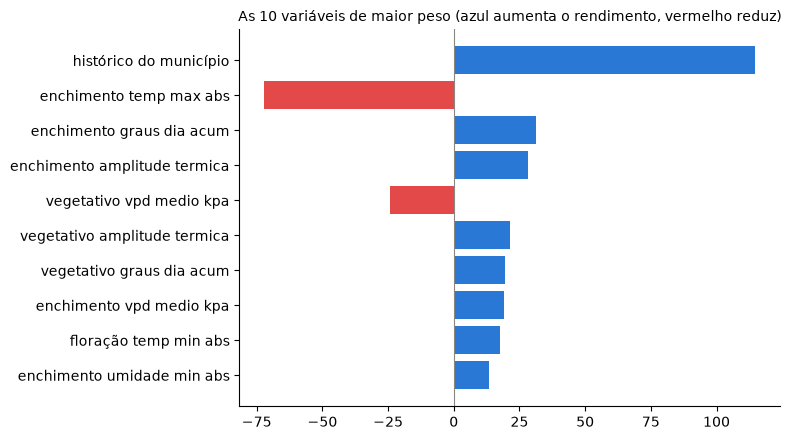

In [13]:
# CÉLULA 4 — modelo final (todas as safras): o peso de cada variável
final = novo_modelo().set_params(cv=GroupKFold(n_splits=5))
final.fit(X.fillna(X.median()), y, groups=municipio)
coef = pd.Series(final.best_estimator_.named_steps["modelo"].coef_, index=X_COLS)
print(f"Variáveis mantidas: {(coef != 0).sum()} de {len(coef)}   |   zeradas pelo próprio modelo: {(coef == 0).sum()}")

nome = lambda v: "histórico do município" if v == "base_hist" else v.replace("floracao", "floração").replace("_", " ")
maiores = coef.reindex(coef.abs().sort_values(ascending=False).index)[:10][::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh([nome(v) for v in maiores.index], maiores.values, color=["#2a78d6" if v > 0 else "#e34948" for v in maiores.values])
ax.axvline(0, color="#898781", lw=0.8)
ax.set_title("As 10 variáveis de maior peso (azul aumenta o rendimento, vermelho reduz)", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()